# Градиенты, Sobel, Laplacian и карта границ



**Цель:** Понять границы как пространственные производные и исследовать шумочувствительность.

**Входные данные:** `images/source/coins.png`, `images/source/brick.png`, `images/source/page.png`

**Формула:** G = √(Gx² + Gy²), θ = atan2(Gy,Gx), ΔI = Ixx + Iyy.

## Последовательность выполнения

1. Построить карты Gx и Gy для coins.png посредством cv2.Sobel с CV_32F. Отдельно показать отрицательные значения без потери знака.
2. Посчитать модуль градиента и ориентацию θ; для отображения углов перевести в [0,180) градусов.
3. Получить бинарную маску границ при трёх порогах: квантили 0.70, 0.85, 0.95 распределения |G|.
4. Применить Laplacian и сравнить обнаружение контуров с Sobel. Объяснить, почему производная второго порядка чувствительнее к шуму.
5. Провести сравнение на coins.png и brick.png. Как текстура меняет количество ложных границ?
6. Перед Sobel выполнить GaussianBlur σ=1.0 и σ=2.0, сравнить карты границ.

**Ожидаемая проверка:** Контуры монет в Sobel образуют замкнутые или почти замкнутые дуги, а кирпичная текстура вызывает много мелких откликов. Отрицательные Gx/Gy не следует сначала обрезать.

**Оценивание / 10:** Sobel и карты — 3; пороги — 2; Laplacian — 2; сравнение/обсуждение — 3.

**Вопросы:**
- Почему ориентация градиента перпендикулярна локальному контуру?
- Почему предварительное сглаживание уменьшает ложные границы?


[Контрольные вопросы]:
1) Вектор градиента (Gx, Gy) указывает направление наискорейшего возрастания яркости, поэтому он ортогонален касательной к контуру.
2) Вторая производная (Лапласиан) усиливает высокочастотный шум пропорционально квадрату частоты (w^2), в то время как первая производная усиливает шум пропорционально w.



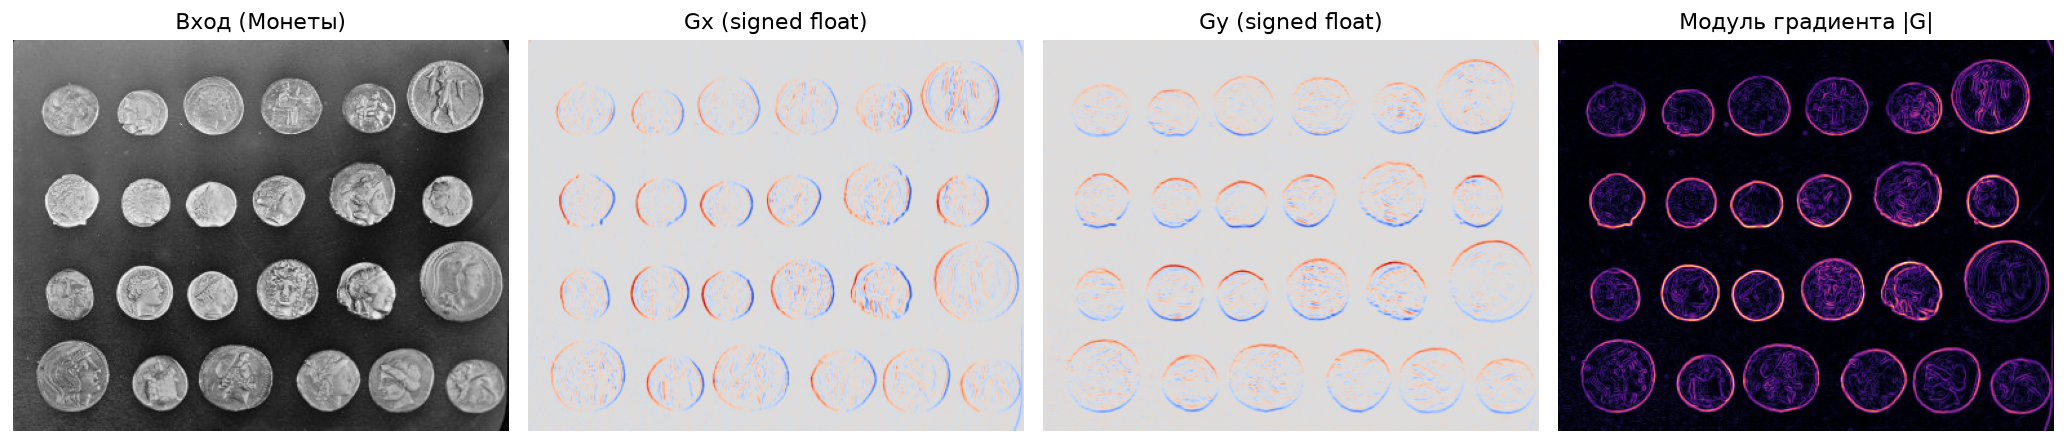

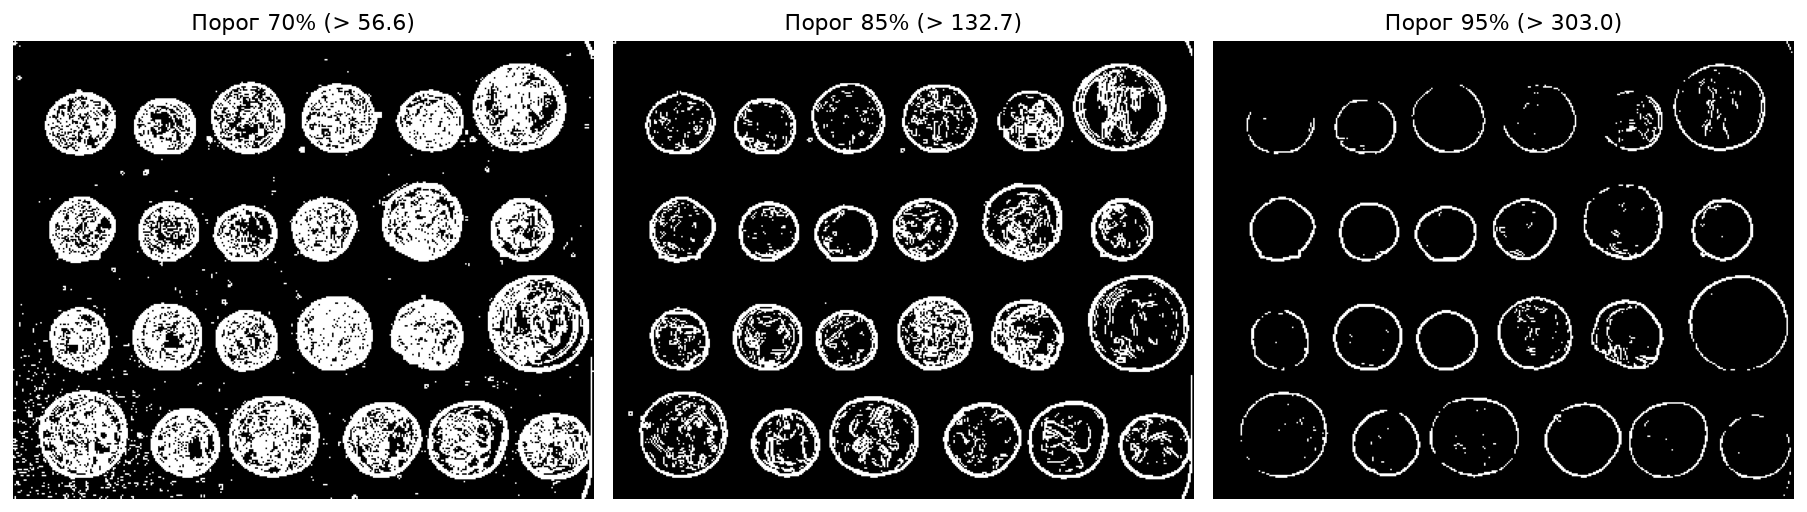

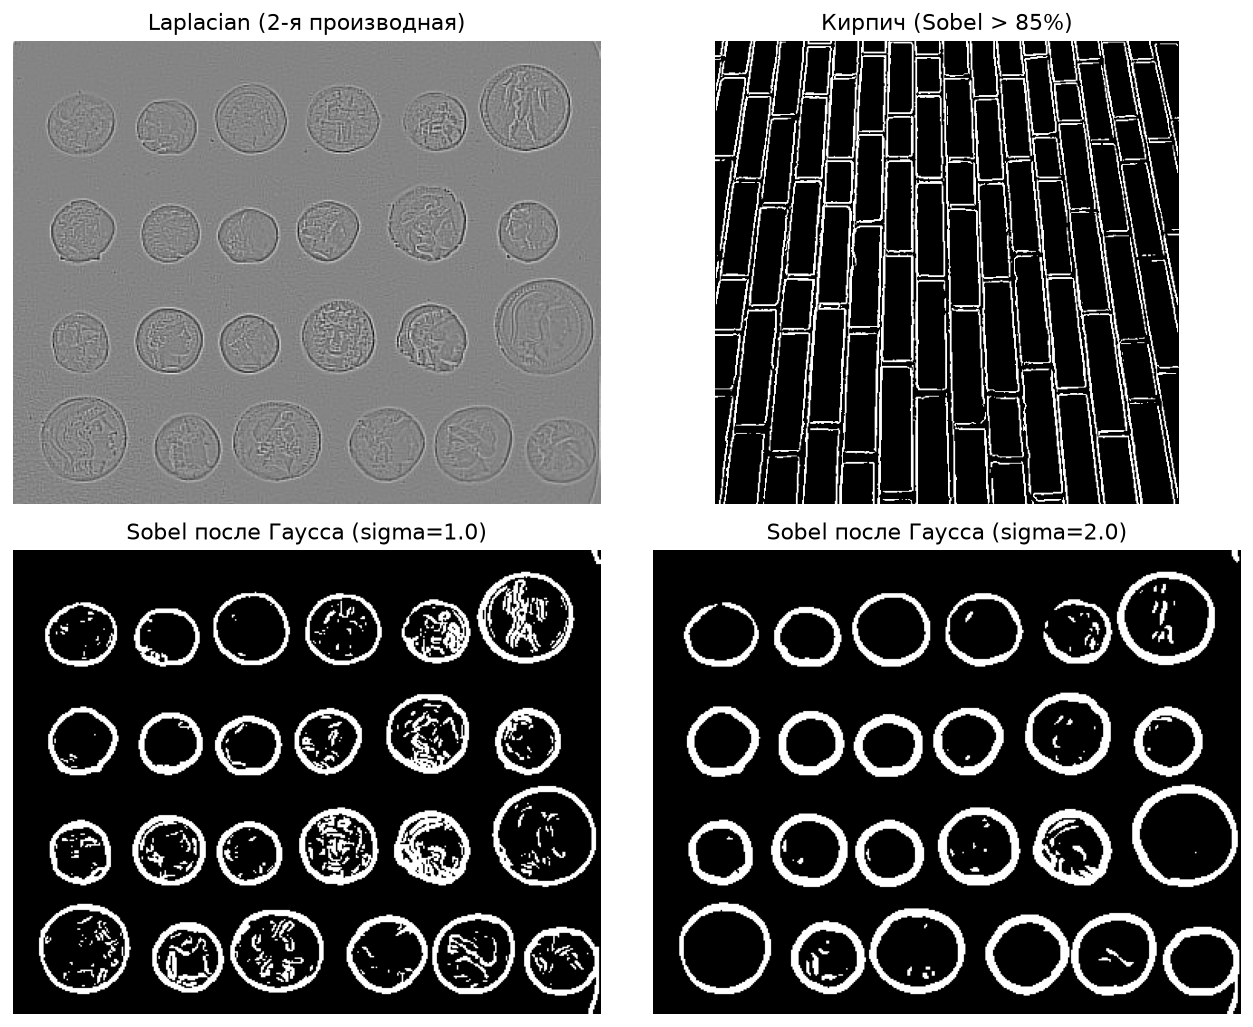

In [1]:
# Полное выполнение заданий Лабораторной работы №4
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent
coins = cv2.imread(str(R/'images/source/coins.png'), cv2.IMREAD_GRAYSCALE)
brick = cv2.imread(str(R/'images/source/brick.png'), cv2.IMREAD_GRAYSCALE)
assert coins is not None and brick is not None

# 1. Вычисление Gx, Gy с сохранением знака (CV_32F)
gx = cv2.Sobel(coins, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(coins, cv2.CV_32F, 0, 1, ksize=3)

# 2. Модуль градиента и ориентация в [0, 180) градусов
mag = np.sqrt(gx**2 + gy**2)
theta = np.arctan2(gy, gx)
theta_deg = np.mod(np.degrees(theta), 180.0)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(coins, cmap='gray'); axes[0].set_title("Вход (Монеты)"); axes[0].axis('off')
axes[1].imshow(gx, cmap='coolwarm'); axes[1].set_title("Gx (signed float)"); axes[1].axis('off')
axes[2].imshow(gy, cmap='coolwarm'); axes[2].set_title("Gy (signed float)"); axes[2].axis('off')
axes[3].imshow(mag, cmap='magma'); axes[3].set_title("Модуль градиента |G|"); axes[3].axis('off')
plt.tight_layout()
plt.show()

# 3. Пороговая бинаризация по квантилям 0.70, 0.85, 0.95
q70 = np.quantile(mag, 0.70)
q85 = np.quantile(mag, 0.85)
q95 = np.quantile(mag, 0.95)
mask70 = (mag > q70).astype(np.uint8)
mask85 = (mag > q85).astype(np.uint8)
mask95 = (mag > q95).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(mask70, cmap='gray'); axes[0].set_title(f"Порог 70% (> {q70:.1f})"); axes[0].axis('off')
axes[1].imshow(mask85, cmap='gray'); axes[1].set_title(f"Порог 85% (> {q85:.1f})"); axes[1].axis('off')
axes[2].imshow(mask95, cmap='gray'); axes[2].set_title(f"Порог 95% (> {q95:.1f})"); axes[2].axis('off')
plt.tight_layout()
plt.show()

# 4. Лапласиан (вторая производная) vs Sobel
lap = cv2.Laplacian(coins, cv2.CV_32F, ksize=3)

# 5-6. Влияние текстуры (кирпич) и предварительного сглаживания
coins_blur1 = cv2.GaussianBlur(coins, (5, 5), 1.0)
coins_blur2 = cv2.GaussianBlur(coins, (7, 7), 2.0)
mag_blur1 = np.sqrt(cv2.Sobel(coins_blur1, cv2.CV_32F, 1, 0)**2 + cv2.Sobel(coins_blur1, cv2.CV_32F, 0, 1)**2)
mag_blur2 = np.sqrt(cv2.Sobel(coins_blur2, cv2.CV_32F, 1, 0)**2 + cv2.Sobel(coins_blur2, cv2.CV_32F, 0, 1)**2)

brick_mag = np.sqrt(cv2.Sobel(brick, cv2.CV_32F, 1, 0)**2 + cv2.Sobel(brick, cv2.CV_32F, 0, 1)**2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(lap, cmap='gray'); axes[0, 0].set_title("Laplacian (2-я производная)"); axes[0, 0].axis('off')
axes[0, 1].imshow(brick_mag > np.quantile(brick_mag, 0.85), cmap='gray'); axes[0, 1].set_title("Кирпич (Sobel > 85%)"); axes[0, 1].axis('off')
axes[1, 0].imshow(mag_blur1 > np.quantile(mag_blur1, 0.85), cmap='gray'); axes[1, 0].set_title("Sobel после Гаусса (sigma=1.0)"); axes[1, 0].axis('off')
axes[1, 1].imshow(mag_blur2 > np.quantile(mag_blur2, 0.85), cmap='gray'); axes[1, 1].set_title("Sobel после Гаусса (sigma=2.0)"); axes[1, 1].axis('off')
plt.tight_layout()
plt.show()

print("""
[Контрольные вопросы]:
1) Вектор градиента (Gx, Gy) указывает направление наискорейшего возрастания яркости, поэтому он ортогонален касательной к контуру.
2) Вторая производная (Лапласиан) усиливает высокочастотный шум пропорционально квадрату частоты (w^2), в то время как первая производная усиливает шум пропорционально w.
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?